# Portfolio risk and business insights

These cells were executed against the real project outputs. The complete training
and SQL implementation is in the linked source modules. This walkthrough reads and
verifies executed artifacts rather than silently retraining the expensive models.
Home Credit is a consumer-lending proxy; validation is random holdout, never true OOT.


In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image
ROOT=Path.cwd()
if not (ROOT/'reports/metrics.json').exists():
    ROOT=ROOT.parent
metrics=json.loads((ROOT/'reports/metrics.json').read_text())


## Segment outcomes

,segment,applications,bads,bad_rate,feature,volume_share,relative_risk
0,Businessman,10,0,0.000000,NAME_INCOME_TYPE,0.000033,0.000000
1,Commercial associate,71617,5360,0.074843,NAME_INCOME_TYPE,0.232892,0.927086
2,Maternity leave,5,2,0.400000,NAME_INCOME_TYPE,0.000016,4.954860
3,Pensioner,55362,2982,0.053864,NAME_INCOME_TYPE,0.180033,0.667217
4,State servant,21703,1249,0.057550,NAME_INCOME_TYPE,0.070576,0.712876
5,Student,18,0,0.000000,NAME_INCOME_TYPE,0.000059,0.000000
6,Unemployed,22,8,0.363636,NAME_INCOME_TYPE,0.000072,4.504418
7,Working,158774,15224,0.095885,NAME_INCOME_TYPE,0.516320,1.187738
8,Cash loans,278232,23221,0.083459,NAME_CONTRACT_TYPE,0.904787,1.033821
9,Revolving loans,29279,1604,0.054783,NAME_CONTRACT_TYPE,0.095213,0.678609


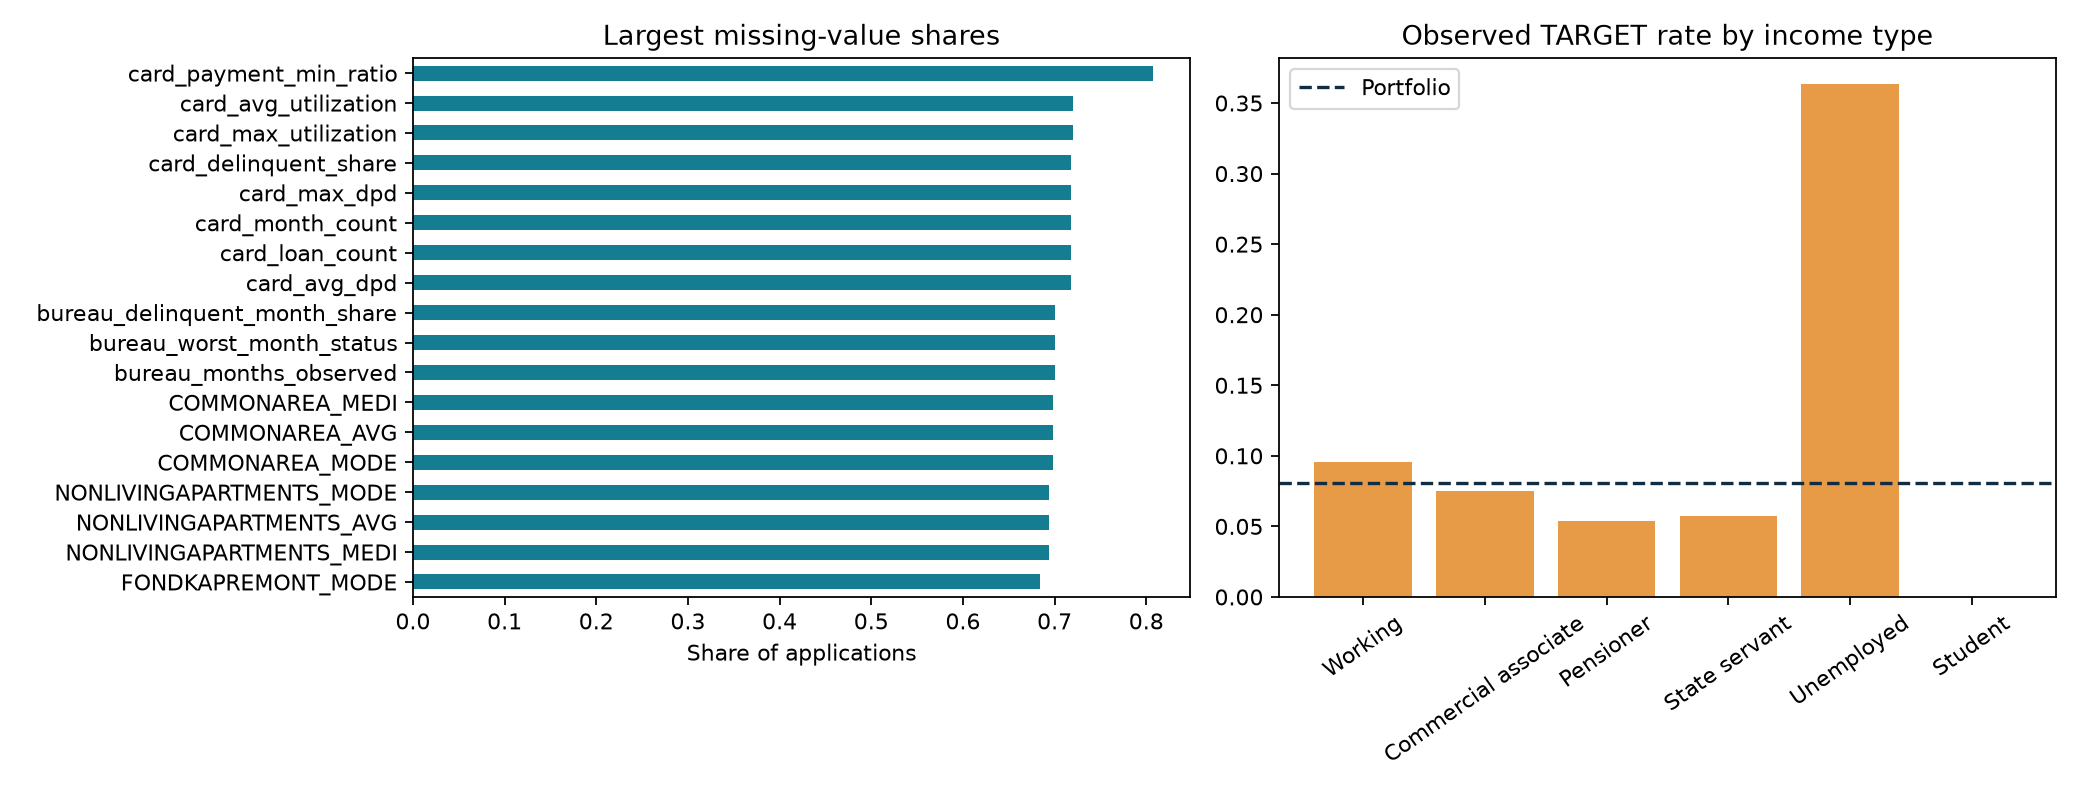

In [2]:
segments=pd.read_csv(ROOT/'reports/segment_risk.csv')
display(segments)
display(Image(filename=str(ROOT/'reports/figures/audit_and_segments.png')))

## Interpretation

Relative risk = segment TARGET rate / overall TARGET rate. Volume share uses the
full labeled application count. These are descriptive associations, not causal effects.
Small segment estimates are uncertain. This EDA does not choose features on holdout.